# Kinase Drug Discovery — Notebook 2
## Ligand-based modelling: QSAR and proteochemometrics (PCM)

**Learning goals**

1. Retrieve and **curate** kinase bioactivity data from ChEMBL (the step that determines model quality more than any algorithm).
2. Build and **validate** a QSAR model for a single kinase (EGFR) — and see how much the validation strategy (random vs scaffold vs temporal split) changes the apparent performance.
3. Understand **y-scrambling** and the **applicability domain**.
4. Build a **proteochemometric (PCM)** model that covers 12 kinases at once by combining compound fingerprints with a description of the **KLIFS binding pocket** (z-scales), and test whether it can extrapolate to a kinase it has never seen.
5. Use the models to look at **kinase selectivity profiles**.

**Hardware / runtime** (4 CPU cores, no GPU, < 45 GB RAM)

| Step | Time (approx.) |
|---|---|
| First-time ChEMBL download of 12 kinases (cached afterwards) | 5–15 min, depends on the ChEMBL server |
| Curation and standardisation | 2–4 min |
| QSAR section | 5 min |
| PCM section | 15–25 min |

Peak memory stays below ~4 GB. All heavy steps are cached in `data/` so re-running is fast. If you are short on time set `MAX_PER_TARGET` lower (e.g. 1500) in the configuration cell.

## 0. Setup and configuration

In [1]:
import os
N_CPU = min(4, os.cpu_count() or 1)
for _v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"]:
    os.environ.setdefault(_v, str(N_CPU))

import time, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from tqdm.auto import tqdm
from joblib import Parallel, delayed

from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem.MolStandardize import rdMolStandardize

from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (r2_score, mean_squared_error, roc_auc_score, matthews_corrcoef,
                             balanced_accuracy_score)
from scipy.stats import pearsonr, spearmanr

RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(context="notebook", style="whitegrid")
pd.set_option("display.width", 160)

DATA = Path("data"); DATA.mkdir(exist_ok=True)
SEED = 42
rng = np.random.default_rng(SEED)
print("Using", N_CPU, "CPU threads")

Using 4 CPU threads


In [2]:
# ----------------------------- configuration -----------------------------
# 12 human kinases: ChEMBL single-protein target IDs
TARGETS = {
    "EGFR":  "CHEMBL203",  "ERBB2": "CHEMBL1824", "ABL1":  "CHEMBL1862", "SRC":   "CHEMBL267",
    "LCK":   "CHEMBL258",  "BTK":   "CHEMBL5251", "KIT":   "CHEMBL1936", "KDR":   "CHEMBL279",
    "FLT3":  "CHEMBL1974", "JAK2":  "CHEMBL2971", "AURKA": "CHEMBL4722", "CDK2":  "CHEMBL301",
}
ACTIVITY_TYPES = ["IC50", "Ki", "Kd", "EC50"]
ACTIVE_THRESHOLD = 6.5     # pChEMBL >= 6.5 (~316 nM) counts as "active" (Papyrus convention)
MAX_PER_TARGET = 3000      # subsample per kinase for the PCM part (None = use everything)
QSAR_TARGET = "EGFR"
N_TREES = 200

## 1. Retrieving bioactivity data from ChEMBL

We use the ChEMBL REST API and request only activities with a **pChEMBL value** (= −log10 of a molar IC50/Ki/Kd/EC50, standardised by ChEMBL). Results are cached as `data/chembl_<ID>.csv.gz`. The public API occasionally returns *500 Internal Server Error* for large requests; the code then automatically retries with simpler, smaller requests, and an interrupted download resumes where it stopped (`data/chembl_<ID>.partial.json`). The IC50/Ki/Kd/EC50 filter is applied locally.

> **Working offline / when the ChEMBL API is down.** If you have a local ChEMBL database, export the result of the query below to `data/chembl_36_kinases.csv` (comma- or tab-separated, with a header). The next cell uses that file automatically and does not contact the API.
>
> ```sql
> SELECT md.chembl_id AS molecule_chembl_id, cs.canonical_smiles AS canonical_smiles,
>        act.pchembl_value AS pchembl_value, act.standard_type AS standard_type,
>        act.standard_relation AS standard_relation, a.chembl_id AS assay_chembl_id,
>        a.assay_type AS assay_type, td.chembl_id AS target_chembl_id,
>        act.data_validity_comment AS data_validity_comment, act.potential_duplicate AS potential_duplicate,
>        d.chembl_id AS document_chembl_id, d.year AS document_year
> FROM chembl_36.activities act
> JOIN chembl_36.assays a              ON a.assay_id  = act.assay_id
> JOIN chembl_36.target_dictionary td  ON td.tid      = a.tid
> JOIN chembl_36.molecule_dictionary md ON md.molregno = act.molregno
> LEFT JOIN chembl_36.compound_structures cs ON cs.molregno = act.molregno
> LEFT JOIN chembl_36.docs d           ON d.doc_id    = act.doc_id
> WHERE td.chembl_id IN ('CHEMBL203','CHEMBL1824','CHEMBL1862','CHEMBL267','CHEMBL258','CHEMBL5251',
>                        'CHEMBL1936','CHEMBL279','CHEMBL1974','CHEMBL2971','CHEMBL4722','CHEMBL301')
>   AND act.pchembl_value IS NOT NULL
>   AND act.standard_type IN ('IC50','Ki','Kd','EC50');
> ```

> **Tip — Papyrus.** For larger studies, use the **Papyrus** dataset (Béquignon *et al.*, J Cheminform 2023; `pip install papyrus-scripts`), which aggregates and standardises ChEMBL, ExCAPE-DB and other sources with quality labels. The ChEMBL API is used here because it requires no large download.

In [3]:
CHEMBL_API = "https://www.ebi.ac.uk/chembl/api/data/activity.json"
FIELDS = ["molecule_chembl_id", "canonical_smiles", "pchembl_value", "standard_type", "standard_relation",
          "assay_chembl_id", "assay_type", "target_chembl_id", "data_validity_comment",
          "potential_duplicate", "document_chembl_id", "document_year"]

# The ChEMBL server sometimes answers large or field-restricted queries with "500 Internal Server Error"
# (time-outs on its side). We therefore fall back to progressively simpler/smaller requests:
#   (page size, use the 'only=' field selection)
STRATEGIES = [(1000, True), (1000, False), (500, False), (200, False), (100, False)]
ECHO_URLS = True        # print every URL before it is sent (copy-paste it into a browser or curl to check)
session = requests.Session()
session.headers.update({"Accept": "application/json", "User-Agent": "kinase-course-notebook"})

class ChEMBLError(RuntimeError):
    pass

def get_page(target_id, offset, level, attempts_per_level=3):
    """Fetch one page starting at `offset`; on server errors step down to simpler requests.
    Returns (json, level_used)."""
    while level < len(STRATEGIES):
        page_size, use_only = STRATEGIES[level]
        params = {"target_chembl_id": target_id, "pchembl_value__isnull": "false",
                  "limit": page_size, "offset": offset}
        if use_only:
            params["only"] = ",".join(FIELDS)
        for attempt in range(1, attempts_per_level + 1):
            try:
                prepared = session.prepare_request(requests.Request("GET", CHEMBL_API, params=params))
                if ECHO_URLS:
                    print(f"  GET {prepared.url}", flush=True)
                r = session.send(prepared, timeout=180)
                if r.status_code == 429:                      # rate limited: wait and retry
                    time.sleep(int(r.headers.get("Retry-After", 30)))
                    continue
                r.raise_for_status()
                return r.json(), level
            except (requests.HTTPError, requests.ConnectionError, requests.Timeout, ValueError) as exc:
                resp = getattr(exc, "response", None)
                code = getattr(resp, "status_code", None)
                if resp is not None and resp.text:
                    print(f"  server said: {resp.text[:300]!r}")
                print(f"  {target_id} offset {offset}: {type(exc).__name__} {code or ''} "
                      f"(page size {page_size}, only={use_only}, attempt {attempt})")
                if code is not None and 400 <= code < 500:
                    break                                     # client error: retrying the same request won't help
                time.sleep(5 * attempt)
        level += 1
        if level < len(STRATEGIES):
            print(f"  -> switching to simpler request: page size {STRATEGIES[level][0]}, only={STRATEGIES[level][1]}")
    raise ChEMBLError(f"ChEMBL API keeps failing for {target_id} at offset {offset}. "
                      "Check https://www.ebi.ac.uk/chembl/ (maintenance?) and re-run this cell later — "
                      "pages already downloaded are kept and the download resumes where it stopped.")

def fetch_chembl_activities(target_id):
    """All activities with a pChEMBL value for one target. Cached in data/; resumable after an interruption."""
    cache = DATA / f"chembl_{target_id}.csv.gz"
    if cache.exists():
        return pd.read_csv(cache)
    partial = DATA / f"chembl_{target_id}.partial.json"
    state = json.loads(partial.read_text()) if partial.exists() else {"offset": 0, "level": 0, "rows": []}
    rows, offset, level, total = state["rows"], state["offset"], state["level"], None
    if offset:
        print(f"{target_id}: resuming at record {offset}")
    with tqdm(desc=target_id, unit=" records", initial=offset) as bar:
        while total is None or offset < total:
            page, level = get_page(target_id, offset, level)
            acts = page.get("activities", [])
            total = page["page_meta"]["total_count"]
            bar.total = total
            if not acts:
                break
            rows.extend({k: a.get(k) for k in FIELDS} for a in acts)
            offset += len(acts)
            bar.update(len(acts))
            partial.write_text(json.dumps({"offset": offset, "level": level, "rows": rows}))
            time.sleep(0.2)                                   # be polite to the public server
    df = pd.DataFrame(rows).reindex(columns=FIELDS)
    df = df[df.standard_type.isin(ACTIVITY_TYPES)]          # IC50/Ki/Kd/EC50 filter applied locally
    df.to_csv(cache, index=False)
    partial.unlink(missing_ok=True)
    return df

# ---- Option A: a CSV exported from a local ChEMBL database (see the SQL query in the markdown above) ----
LOCAL_CSV = DATA / "chembl_36_kinases.csv"     # also accepts .csv.gz / .tsv; set to None to always use the API

def load_local_csv(path):
    """Read the SQL export, normalise column names/NULLs and map ChEMBL target IDs to gene names."""
    path = Path(path)
    opener = __import__("gzip").open if path.suffix == ".gz" else open
    with opener(path, "rt", encoding="utf-8", errors="replace") as fh:
        header = fh.readline()
    sep = max(["\t", ",", ";", "|"], key=header.count)          # detect the delimiter from the header
    df = pd.read_csv(path, sep=sep, na_values=["NULL", "null", "\\N", "None"], low_memory=False)
    # 'chembl_36.activities.pchembl_value', '"PCHEMBL_VALUE"' ... -> 'pchembl_value'
    df.columns = [str(c).strip().strip('"`\'').split(".")[-1].lower() for c in df.columns]
    missing = [c for c in FIELDS if c not in df.columns]
    if missing:
        raise ValueError(f"{path.name} lacks the columns {missing}; found {list(df.columns)}. "
                         "Use the aliases from the SQL query (AS molecule_chembl_id, ...).")
    df["pchembl_value"] = pd.to_numeric(df.pchembl_value, errors="coerce")
    df = df[df.standard_type.isin(ACTIVITY_TYPES)]
    df["gene"] = df.target_chembl_id.map({tid: gene for gene, tid in TARGETS.items()})
    if df.gene.isna().any():
        print(f"ignoring {df.gene.isna().sum()} rows for targets not in TARGETS")
    absent = [g for g, tid in TARGETS.items() if tid not in set(df.target_chembl_id)]
    if absent:
        print("WARNING: no rows in the CSV for", absent)
    return df.dropna(subset=["gene"])[["gene"] + FIELDS].reset_index(drop=True)

# ---- Option B: the ChEMBL REST API (used when no local CSV is present) ----
if LOCAL_CSV is not None and Path(LOCAL_CSV).exists():
    print(f"Loading local ChEMBL export: {LOCAL_CSV}")
    raw = load_local_csv(LOCAL_CSV)
else:
    print("No local CSV found -> downloading from the ChEMBL web API")
    raw = pd.concat({gene: fetch_chembl_activities(tid) for gene, tid in TARGETS.items()},
                    names=["gene", None]).reset_index(level=0).reset_index(drop=True)
print(raw.shape)
raw.groupby("gene").size().rename("raw records").to_frame().T

Loading local ChEMBL export: data/chembl_36_kinases.csv
(107737, 13)


gene,ABL1,AURKA,BTK,CDK2,EGFR,ERBB2,FLT3,JAK2,KDR,KIT,LCK,SRC
raw records,6306,4164,17174,3396,20495,3504,6331,18004,14233,5631,2967,5532


**Troubleshooting the download.** If the cell above fails, run the diagnostic cell below. It sends three increasingly specific requests and echoes each URL, so you can paste them into a browser or `curl` to see which part the server rejects. If even the status request fails, ChEMBL is down or blocked by your network or proxy.

In [4]:
def probe(url, params=None):
    prepared = session.prepare_request(requests.Request("GET", url, params=params))
    print("GET", prepared.url)
    try:
        r = session.send(prepared, timeout=60)
        print("   ->", r.status_code, r.reason, "|", r.text[:200].replace("\n", " "), "\n")
    except Exception as exc:
        print("   ->", type(exc).__name__, exc, "\n")

probe("https://www.ebi.ac.uk/chembl/api/data/status.json")
probe(CHEMBL_API, {"target_chembl_id": "CHEMBL203", "limit": 1})
probe(CHEMBL_API, {"target_chembl_id": "CHEMBL203", "pchembl_value__isnull": "false", "limit": 1})
probe(CHEMBL_API, {"target_chembl_id": "CHEMBL203", "pchembl_value__isnull": "false", "limit": 1,
                   "only": ",".join(FIELDS)})

GET https://www.ebi.ac.uk/chembl/api/data/status.json
   -> 200 OK | {"activities": 24527044, "chembl_db_version": "ChEMBL_37", "chembl_release_date": "2026-05-01", "compound_records": 3824604, "disinct_compounds": 2921148, "publications": 101100, "status": "UP", "targ 

GET https://www.ebi.ac.uk/chembl/api/data/activity.json?target_chembl_id=CHEMBL203&limit=1
   -> 200 OK | {"activities": [{"action_type": null, "activity_comment": null, "activity_id": 32260, "activity_properties": [], "assay_chembl_id": "CHEMBL674637", "assay_description": "Inhibitory activity towards ty 

GET https://www.ebi.ac.uk/chembl/api/data/activity.json?target_chembl_id=CHEMBL203&pchembl_value__isnull=false&limit=1
   -> 200 OK | {"activities": [{"action_type": null, "activity_comment": null, "activity_id": 32260, "activity_properties": [], "assay_chembl_id": "CHEMBL674637", "assay_description": "Inhibitory activity towards ty 

GET https://www.ebi.ac.uk/chembl/api/data/activity.json?target_chembl_id=CHEMBL203

## 2. Data curation

Typical curation steps (cf. Fourches *et al.*, J Chem Inf Model 2010; Papyrus):

1. keep exact measurements (`standard_relation == '='`) — censored values (">10 µM") are not usable for regression;
2. keep **binding assays** (`assay_type == 'B'`);
3. drop records flagged by ChEMBL curators (`data_validity_comment`) and **potential duplicates** (the same value reported again in a later paper);
4. **standardise** structures: remove salts/solvents (largest fragment), neutralise charges, canonical SMILES;
5. **aggregate** multiple measurements of the same compound–target pair (median), and record their spread.

In [5]:
df = raw.dropna(subset=["canonical_smiles", "pchembl_value"]).copy()
steps = [("all records with pChEMBL", len(df))]
df = df[df.standard_relation == "="];                              steps.append(("relation '='", len(df)))
df = df[df.assay_type == "B"];                                     steps.append(("binding assays", len(df)))
df = df[df.data_validity_comment.isna()];                          steps.append(("no validity flag", len(df)))
df = df[~df.potential_duplicate.astype(str).str.lower().isin(["1", "true", "1.0"])]
steps.append(("not a potential duplicate", len(df)))
pd.DataFrame(steps, columns=["filter", "records"])

,filter,records
0,all records with pChEMBL,107643
1,relation '=',107643
2,binding assays,101343
3,no validity flag,101343
4,not a potential duplicate,86218


In [6]:
def standardize_smiles(smi):
    """Cleanup -> largest fragment -> neutralise -> canonical SMILES (None on failure)."""
    try:
        m = Chem.MolFromSmiles(smi)
        if m is None:
            return None
        m = rdMolStandardize.Cleanup(m)
        m = rdMolStandardize.LargestFragmentChooser().choose(m)
        m = rdMolStandardize.Uncharger().uncharge(m)
        return Chem.MolToSmiles(m)
    except Exception:
        return None

std_cache = DATA / "standardized_smiles.json"
std_map = json.loads(std_cache.read_text()) if std_cache.exists() else {}
todo = [s for s in df.canonical_smiles.unique() if s not in std_map]
if todo:
    out = Parallel(n_jobs=N_CPU, batch_size=256)(delayed(standardize_smiles)(s) for s in tqdm(todo, desc="standardising"))
    std_map.update(dict(zip(todo, out)))
    std_cache.write_text(json.dumps(std_map))
df["smiles"] = df.canonical_smiles.map(std_map)
df = df.dropna(subset=["smiles"])
print(f"{df.smiles.nunique()} unique standardised compounds")

standardising:   0%|          | 0/55544 [00:00<?, ?it/s]

55344 unique standardised compounds


In [7]:
agg = (df.groupby(["gene", "smiles"])
         .agg(pchembl=("pchembl_value", "median"),
              pchembl_std=("pchembl_value", "std"),
              n_measurements=("pchembl_value", "size"),
              year=("document_year", "min"),
              chembl_id=("molecule_chembl_id", "first"))
         .reset_index())
agg["active"] = (agg.pchembl >= ACTIVE_THRESHOLD).astype(int)
agg.to_csv(DATA / "kinase_dataset_curated.csv.gz", index=False)

overview = agg.groupby("gene").agg(compounds=("smiles", "size"), median_pchembl=("pchembl", "median"),
                                   frac_active=("active", "mean")).round(2)
overview.sort_values("compounds", ascending=False)

,compounds,median_pchembl,frac_active
gene,,,
JAK2,11974,7.43,0.76
EGFR,10374,7.01,0.63
KDR,9871,6.84,0.60
BTK,9619,7.52,0.78
SRC,3757,6.62,0.53
FLT3,3731,7.12,0.66
AURKA,3018,7.02,0.64
KIT,2948,6.54,0.51
ABL1,2873,7.45,0.69


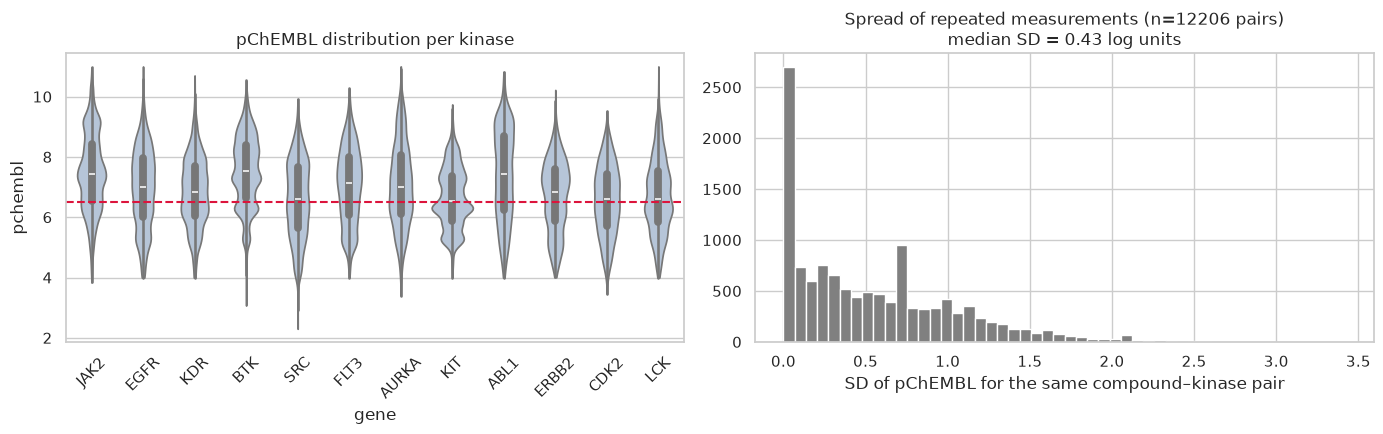

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order = overview.sort_values("compounds", ascending=False).index
sns.violinplot(data=agg, x="gene", y="pchembl", order=order, ax=axes[0], cut=0, color="lightsteelblue")
axes[0].axhline(ACTIVE_THRESHOLD, ls="--", c="crimson"); axes[0].set_title("pChEMBL distribution per kinase")
axes[0].tick_params(axis="x", rotation=45)
rep = agg.dropna(subset=["pchembl_std"])
axes[1].hist(rep.pchembl_std, bins=50, color="grey")
axes[1].set_title(f"Spread of repeated measurements (n={len(rep)} pairs)\nmedian SD = {rep.pchembl_std.median():.2f} log units")
axes[1].set_xlabel("SD of pChEMBL for the same compound–kinase pair")
plt.tight_layout(); plt.show()

The right-hand panel is important: the **experimental uncertainty** of public pChEMBL data is typically ~0.5 log units (Kramer *et al.*, J Med Chem 2012). A model with RMSE ≈ 0.6–0.7 is therefore already close to the noise level — no model can be "better than the data".

## 3. QSAR for a single kinase (EGFR)

### 3.1 Descriptors

We encode molecules as **Morgan fingerprints** (radius 2, 2048 bits; ECFP4-like). Each bit indicates the presence of a circular substructure.

In [9]:
def fingerprints(smiles, radius=2, n_bits=2048):
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=n_bits)
    mols = [Chem.MolFromSmiles(s) for s in smiles]
    X = np.vstack([gen.GetFingerprintAsNumPy(m) for m in mols]).astype(np.uint8)
    bitvects = [gen.GetFingerprint(m) for m in mols]
    return X, bitvects

def regression_metrics(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "Pearson r": pearsonr(y_true, y_pred)[0] if np.std(y_pred) > 0 else np.nan,
            "Spearman ρ": spearmanr(y_true, y_pred)[0] if np.std(y_pred) > 0 else np.nan,
            "n_test": len(y_true)}

qsar = agg[agg.gene == QSAR_TARGET].reset_index(drop=True)
X_q, fps_q = fingerprints(qsar.smiles)
y_q = qsar.pchembl.values
print(f"{QSAR_TARGET}: {X_q.shape[0]} compounds x {X_q.shape[1]} bits")

EGFR: 10374 compounds x 2048 bits


### 3.2 Three ways to split the data

* **Random split** — the test set contains close analogues of training compounds (same paper, same series). Optimistic.
* **Scaffold split** — all compounds sharing a Bemis–Murcko scaffold go to the same set, so the test set contains *new chemotypes*.
* **Temporal split** — train on compounds published up to year *t*, test on later ones. This mimics prospective use and is usually the most realistic (and most pessimistic).

In [10]:
def random_split(n, test_frac=0.2, seed=SEED):
    idx_train, idx_test = train_test_split(np.arange(n), test_size=test_frac, random_state=seed)
    return np.sort(idx_train), np.sort(idx_test)

def scaffold_split(smiles, test_frac=0.2):
    """Largest scaffold groups go to training; small/rare scaffolds end up in the test set."""
    scaffolds = pd.Series([MurckoScaffold.MurckoScaffoldSmiles(smiles=s) for s in smiles])
    groups = scaffolds.groupby(scaffolds).groups
    train, cutoff = [], (1 - test_frac) * len(smiles)
    for _, idx in sorted(groups.items(), key=lambda kv: len(kv[1]), reverse=True):
        if len(train) + len(idx) <= cutoff:
            train.extend(idx)
    train = np.sort(np.array(train))
    test = np.setdiff1d(np.arange(len(smiles)), train)
    return train, test

def temporal_split(years, test_frac=0.2):
    years = pd.Series(years, dtype=float).reset_index(drop=True)
    years = years.fillna(years.max())          # unknown year -> treat as most recent
    cutoff = years.quantile(1 - test_frac)
    train = np.where(years < cutoff)[0]
    test = np.where(years >= cutoff)[0]
    return train, test, int(cutoff)

splits = {"random": random_split(len(qsar)), "scaffold": scaffold_split(qsar.smiles)}
tr, te, cutoff_year = temporal_split(qsar.year)
splits[f"temporal (test ≥ {cutoff_year})"] = (tr, te)
for k, (a, b) in splits.items():
    print(f"{k:28s} train={len(a):6d}  test={len(b):6d}")

random                       train=  8299  test=  2075
scaffold                     train=  8299  test=  2075
temporal (test ≥ 2021)       train=  7523  test=  2851


In [11]:
def make_rf(**kw):
    return RandomForestRegressor(n_estimators=N_TREES, max_features=0.3, min_samples_leaf=1,
                                 n_jobs=N_CPU, random_state=SEED, **kw)

qsar_results, qsar_preds = [], {}
for name, (tr, te) in splits.items():
    t0 = time.time()
    model = make_rf().fit(X_q[tr], y_q[tr])
    pred = model.predict(X_q[te])
    qsar_preds[name] = (te, pred)
    res = regression_metrics(y_q[te], pred)
    res.update(split=name, model="RF", seconds=round(time.time() - t0, 1))
    qsar_results.append(res)
    # baseline: predict the training mean for every compound
    base = regression_metrics(y_q[te], np.full(len(te), y_q[tr].mean()))
    base.update(split=name, model="mean baseline")
    qsar_results.append(base)

pd.DataFrame(qsar_results).set_index(["split", "model"]).round(3)

/tmp/ipykernel_455/1930247893.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "Pearson r": pearsonr(y_true, y_pred)[0] if np.std(y_pred) > 0 else np.nan,
/tmp/ipykernel_455/1930247893.py:12: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "Spearman ρ": spearmanr(y_true, y_pred)[0] if np.std(y_pred) > 0 else np.nan,


R2   RMSE  Pearson r  Spearman ρ  n_test  seconds
split                  model                                                              
random                 RF             0.746  0.658      0.865       0.860    2075    153.3
                       mean baseline -0.001  1.307        NaN         NaN    2075      NaN
scaffold               RF             0.439  0.930      0.686       0.675    2075    143.7
                       mean baseline -0.078  1.289        NaN         NaN    2075      NaN
temporal (test ≥ 2021) RF            -0.593  1.528      0.089       0.010    2851    128.7
                       mean baseline -0.309  1.385        NaN         NaN    2851      NaN

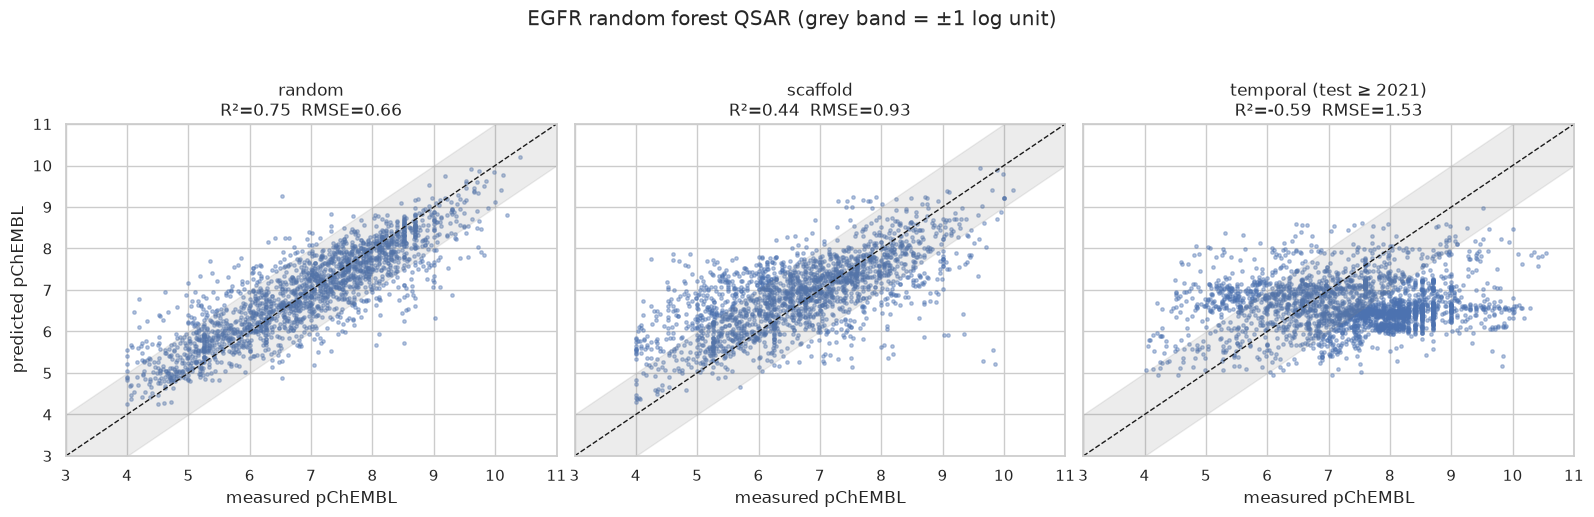

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
for ax, (name, (te, pred)) in zip(axes, qsar_preds.items()):
    ax.scatter(y_q[te], pred, s=6, alpha=0.4)
    lims = [3, 11]; ax.plot(lims, lims, "k--", lw=1)
    ax.fill_between(lims, [l - 1 for l in lims], [l + 1 for l in lims], color="grey", alpha=0.15)
    r = regression_metrics(y_q[te], pred)
    ax.set_title(f"{name}\nR²={r['R2']:.2f}  RMSE={r['RMSE']:.2f}")
    ax.set_xlabel("measured pChEMBL"); ax.set_xlim(lims); ax.set_ylim(lims)
axes[0].set_ylabel("predicted pChEMBL")
plt.suptitle(f"{QSAR_TARGET} random forest QSAR (grey band = ±1 log unit)", y=1.03)
plt.tight_layout(); plt.show()

**Observations to discuss**

* Performance drops from random → scaffold → temporal split. Which number would you report to a medicinal chemist who wants to use the model for *new* compound series?
* Note the "regression to the mean": the model under-predicts the most potent and over-predicts the least potent compounds. Random forests average over training values and cannot extrapolate beyond the observed range.

### 3.3 Y-scrambling (randomisation test)

If a model trained on **shuffled** labels performs as well as the real model, the original model learned nothing meaningful (chance correlation). With 2048 descriptors and a few thousand compounds this sanity check is worth doing.

In [13]:
tr, te = splits["random"]
scr = []
for i in range(3):
    y_shuffled = rng.permutation(y_q[tr])
    m = make_rf().fit(X_q[tr], y_shuffled)
    scr.append(regression_metrics(y_q[te], m.predict(X_q[te]))["R2"])
print("R² with real labels    :", round(qsar_results[0]["R2"], 3))
print("R² with scrambled labels:", np.round(scr, 3))

R² with real labels    : 0.746
R² with scrambled labels: [-0.156 -0.165 -0.118]


### 3.4 Applicability domain

A model is only reliable for compounds that resemble its training set. A simple applicability-domain (AD) measure is the **Tanimoto similarity to the nearest training compound**. Let's see how the prediction error depends on it (scaffold split).

In [ ]:
tr, te = splits["scaffold"]
te_idx, pred = qsar_preds["scaffold"]
train_fps = [fps_q[i] for i in tr]
nn_sim = np.array([max(DataStructs.BulkTanimotoSimilarity(fps_q[i], train_fps)) for i in te_idx])
abs_err = np.abs(y_q[te_idx] - pred)

bins = [0, 0.3, 0.4, 0.5, 0.6, 0.7, 1.01]
ad = pd.DataFrame({"nn_sim": nn_sim, "abs_err": abs_err})
ad["similarity bin"] = pd.cut(ad.nn_sim, bins, right=False)
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=ad, x="similarity bin", y="abs_err", ax=ax, color="lightsteelblue", showfliers=False)
for i, (b, grp) in enumerate(ad.groupby("similarity bin", observed=False)):
    ax.text(i, ax.get_ylim()[1] * 0.95, f"n={len(grp)}", ha="center", fontsize=8)
ax.set_ylabel("|error| (log units)"); ax.set_xlabel("Tanimoto similarity to nearest training compound")
ax.set_title("Prediction error vs. distance to training set (scaffold split)")
plt.tight_layout(); plt.show()

### 3.5 Classification: active vs inactive

In virtual screening we often only need to **rank** or **classify** compounds. Using the threshold pChEMBL ≥ 6.5 we train a random-forest classifier and evaluate it with ROC-AUC, Matthews correlation coefficient (MCC) and balanced accuracy — metrics that are robust to class imbalance (plain accuracy is not).

In [ ]:
yc = (y_q >= ACTIVE_THRESHOLD).astype(int)
clf_res = []
for name, (tr, te) in splits.items():
    clf = RandomForestClassifier(n_estimators=N_TREES, max_features="sqrt", class_weight="balanced",
                                 n_jobs=N_CPU, random_state=SEED).fit(X_q[tr], yc[tr])
    proba = clf.predict_proba(X_q[te])[:, 1]
    clf_res.append({"split": name, "frac_active_test": yc[te].mean(),
                    "ROC-AUC": roc_auc_score(yc[te], proba),
                    "MCC": matthews_corrcoef(yc[te], proba >= 0.5),
                    "balanced acc.": balanced_accuracy_score(yc[te], proba >= 0.5)})
pd.DataFrame(clf_res).set_index("split").round(3)

**Exercise 2.1** — Descriptor choice. Re-run the scaffold-split regression with (a) Morgan radius 3, (b) 1024 bits, (c) a set of ~200 RDKit 2D descriptors (`from rdkit.Chem import Descriptors; Descriptors.CalcMolDescriptors(mol)`, RDKit ≥ 2023.03). Which works best? Is the difference larger than the variation you get from changing the random seed?

<details><summary><b>Solution sketch</b></summary>

```python
tr, te = splits["scaffold"]
for radius, bits in [(2, 2048), (3, 2048), (2, 1024)]:
    X, _ = fingerprints(qsar.smiles, radius=radius, n_bits=bits)
    m = make_rf().fit(X[tr], y_q[tr])
    print(radius, bits, regression_metrics(y_q[te], m.predict(X[te])))

from rdkit.Chem import Descriptors
D = pd.DataFrame([Descriptors.CalcMolDescriptors(Chem.MolFromSmiles(s)) for s in qsar.smiles])
D = D.replace([np.inf, -np.inf], np.nan).fillna(0).values.astype(np.float32)
m = make_rf().fit(D[tr], y_q[tr])
print("RDKit 2D", regression_metrics(y_q[te], m.predict(D[te])))
```
Differences between reasonable fingerprints are usually small (a few hundredths in R²), often comparable to seed-to-seed variation — data and split matter more than the descriptor.
</details>

In [ ]:
# Your answer to Exercise 2.1 here

**Exercise 2.2** — A *k*-nearest-neighbour model (predict the mean pChEMBL of the 5 most similar training compounds) is a strong and interpretable baseline. Implement it with Tanimoto similarity and compare it with the random forest on the three splits.

<details><summary><b>Solution sketch</b></summary>

```python
def knn_predict(train_idx, test_idx, k=5):
    tfps = [fps_q[i] for i in train_idx]
    preds = []
    for i in test_idx:
        sims = np.array(DataStructs.BulkTanimotoSimilarity(fps_q[i], tfps))
        nn = np.argsort(-sims)[:k]
        preds.append(y_q[train_idx][nn].mean())
    return np.array(preds)

for name, (tr, te) in splits.items():
    print(name, regression_metrics(y_q[te], knn_predict(tr, te)))
```
</details>

In [ ]:
# Your answer to Exercise 2.2 here

## 4. Proteochemometrics (PCM)

A QSAR model describes **one** target. PCM models the **compound–target pair**:

$$\text{pActivity} = f(\text{compound descriptors},\ \text{protein descriptors})$$

so one model learns from *all* kinases simultaneously and can share information between related binding sites (van Westen *et al.*, Med Chem Commun 2011; Lapinsh *et al.*, 2001).

**Protein descriptors.** We use the 85 aligned KLIFS pocket residues (Notebook 1) and encode each residue with the 5 **z-scales** of Sandberg *et al.* (J Med Chem 1998) — principal components of 26 physicochemical properties (z1 ≈ lipophilicity, z2 ≈ size/polarisability, z3 ≈ polarity/charge, z4–z5 ≈ electronegativity, heat of formation, hardness). Gaps are encoded as zeros. Result: 85 × 5 = **425 protein descriptors**. Because the pocket is aligned, descriptor *j* means the same thing in every kinase.

In [ ]:
KLIFS_POCKETS = {
    "EGFR":  "KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLITQLMPFGCLLDYVREYLEDRRLVHRDLAARNVLVITDFGLA",
    "ERBB2": "KVLGSGAFGTVYKVAIKVLEILDEAYVMAGVGPYVSRLLGIQLVTQLMPYGCLLDHVREYLEDVRLVHRDLAARNVLVITDFGLA",
    "ABL1":  "HKLGGGQYGEVYEVAVKTLEFLKEAAVMKEIKPNLVQLLGVYIITEFMTYGNLLDYLREYLEKKNFIHRDLAARNCLVVADFGLS",
    "SRC":   "VKLGQGCFGEVWMVAIKTLAFLQEAQVMKKLREKLVQLYAVYIVTEYMSKGSLLDFLKGYVERMNYVHRDLRAANILVVADFGLA",
    "LCK":   "ERLGAGQFGEVWMVAVKSLAFLAEANLMKQLQQRLVRLYAVYIITEYMENGSLVDFLKTFIEERNYIHRDLRAANILVIADFGLA",
    "BTK":   "KELGTGQFGVVKYVAIKMIEFIEEAKVMMNLSEKLVQLYGVFIITEYMANGCLLNYLREYLESKQFLHRDLAARNCLVVSDFGLS",
    "KIT":   "KTLGAGAFGKVVEVAVKMLALMSELKVLSYLGMNIVNLLGALVITEYCCYGDLLNFLRRFLASKNCIHRDLAARNILLICDFGLA",
    "KDR":   "KPLGRGAFGQVIEVAVKMLALMSELKILIHIGLNVVNLLGAMVIVEFCKFGNLSTYLRSFLASRKCIHRDLAARNILLICDFGLA",
    "FLT3":  "KVLGSGAFGKVMNVAVKMLALMSELKMMTQLGENIVNLLGAYLIFEYCCYGDLLNYLRSFLEFKSCVHRDLAARNVLVICDFGLA",
    "JAK2":  "QQLGKGNFGSVEMVAVKKLDFEREIEILKSLQDNIVKYKGVKLIMEYLPYGSLRDYLQKYLGTKRYIHRDLATRNILVIGDFGLT",
    "AURKA": "RPLGKGKFGNVYLLALKVLQLRREVEIQSHLRPNILRLYGYYLILEYAPLGTVYRELQKYCHSKRVIHRDIKPENLLLIADFGWS",
    "CDK2":  "EKIGEGTYGVVYKVALKKITAIREISLLKELNPNIVKLLDVYLVFEFLH-QDLKKFMDAFCHSHRVLHRDLKPQNLLILADFGLA",
}

# Sandberg et al. (1998) z-scales z1..z5
ZSCALES = {
    "A": [0.24, -2.32, 0.60, -0.14, 1.30],  "R": [3.52, 2.50, -3.50, 1.99, -0.17],
    "N": [3.05, 1.62, 1.04, -1.15, 1.61],   "D": [3.98, 0.93, 1.93, -2.46, 0.75],
    "C": [0.84, -1.67, 3.71, 0.18, -2.65],  "Q": [1.75, 0.50, -1.44, -1.34, 0.66],
    "E": [3.11, 0.26, -0.11, -3.04, -0.25], "G": [2.05, -4.06, 0.36, -0.82, -0.38],
    "H": [2.47, 1.95, 0.26, 3.90, 0.09],    "I": [-3.89, -1.73, -1.71, -0.84, 0.26],
    "L": [-4.28, -1.30, -1.49, -0.72, 0.84], "K": [2.29, 0.89, -2.49, 1.49, 0.31],
    "M": [-2.85, -0.22, 0.47, 1.94, -0.98], "F": [-4.22, 1.94, 1.06, 0.54, -0.62],
    "P": [-1.66, 0.27, 1.84, 0.70, 2.00],   "S": [2.39, -1.07, 1.15, -1.39, 0.67],
    "T": [0.75, -2.18, -1.12, -1.46, -0.40], "W": [-4.36, 3.94, 0.59, 3.44, -1.59],
    "Y": [-2.54, 2.44, 0.43, 0.04, -1.47],  "V": [-2.59, -2.64, -1.54, -0.85, -0.02],
    "-": [0.0, 0.0, 0.0, 0.0, 0.0],
}

def pocket_zscales(pocket):
    return np.array([ZSCALES.get(aa, ZSCALES["-"]) for aa in pocket], dtype=np.float32).ravel()

GENES = list(TARGETS)
PROT_Z = np.vstack([pocket_zscales(KLIFS_POCKETS[g]) for g in GENES])      # 12 x 425
PROT_ONEHOT = np.eye(len(GENES), dtype=np.float32)                            # 12 x 12 ("identity" descriptor)
print("z-scale protein descriptor matrix:", PROT_Z.shape)

In [ ]:
# PCM dataset: (optionally) subsample per kinase to keep training times short on 4 cores
parts = []
for g in GENES:
    sub = agg[agg.gene == g]
    if MAX_PER_TARGET and len(sub) > MAX_PER_TARGET:
        sub = sub.sample(MAX_PER_TARGET, random_state=SEED)
    parts.append(sub)
pcm = pd.concat(parts, ignore_index=True)
pcm["gene_idx"] = pcm.gene.map({g: i for i, g in enumerate(GENES)})

uniq_smiles = pcm.smiles.unique()
cmp_index = {s: i for i, s in enumerate(uniq_smiles)}
pcm["cmp_idx"] = pcm.smiles.map(cmp_index)
FP_PCM, FPS_PCM = fingerprints(uniq_smiles, radius=2, n_bits=1024)
print(f"PCM set: {len(pcm)} activities, {len(uniq_smiles)} compounds, {len(GENES)} kinases")

def build_X(rows, protein="zscales"):
    lig = FP_PCM[rows.cmp_idx.values].astype(np.float32)
    if protein is None:
        return lig
    P = PROT_Z if protein == "zscales" else PROT_ONEHOT
    return np.hstack([lig, P[rows.gene_idx.values]])

def make_rf_pcm():
    return RandomForestRegressor(n_estimators=N_TREES, max_features=0.2, min_samples_leaf=2,
                                 n_jobs=N_CPU, random_state=SEED)

### 4.1 Random split: does PCM beat single-target QSAR?

We compare four models on the same random 80/20 split (stratified by kinase):

| Model | Descriptors | Note |
|---|---|---|
| **QSAR (per kinase)** | fingerprint | 12 independent models |
| **Ligand-only (global)** | fingerprint | one model, ignores which kinase — predicts the same value for every kinase |
| **PCM one-hot** | fingerprint + kinase identity | protein descriptor carries no biology |
| **PCM z-scales** | fingerprint + KLIFS pocket z-scales | protein descriptor encodes physicochemistry of the pocket |

In [ ]:
train_idx, test_idx = train_test_split(np.arange(len(pcm)), test_size=0.2, random_state=SEED, stratify=pcm.gene)
p_tr, p_te = pcm.iloc[train_idx], pcm.iloc[test_idx]
preds = {}

t0 = time.time()
qsar_pred = np.zeros(len(p_te))
for g in GENES:
    mtr, mte = (p_tr.gene == g).values, (p_te.gene == g).values
    m = make_rf_pcm().fit(build_X(p_tr[mtr], None), p_tr.pchembl[mtr])
    qsar_pred[mte] = m.predict(build_X(p_te[mte], None))
preds["QSAR (per kinase)"] = qsar_pred
print(f"per-kinase QSAR done in {time.time() - t0:.0f}s")

for name, prot in [("Ligand-only (global)", None), ("PCM one-hot", "onehot"), ("PCM z-scales", "zscales")]:
    t0 = time.time()
    m = make_rf_pcm().fit(build_X(p_tr, prot), p_tr.pchembl)
    preds[name] = m.predict(build_X(p_te, prot))
    print(f"{name} done in {time.time() - t0:.0f}s")

In [ ]:
rows = []
for name, pr in preds.items():
    for g in GENES:
        mask = (p_te.gene == g).values
        r = regression_metrics(p_te.pchembl.values[mask], pr[mask]); r.update(model=name, gene=g)
        rows.append(r)
    r = regression_metrics(p_te.pchembl.values, pr); r.update(model=name, gene="ALL")
    rows.append(r)
res_random = pd.DataFrame(rows)

pivot = res_random.pivot(index="gene", columns="model", values="R2").loc[GENES + ["ALL"]]
display(pivot.round(3))
pivot.drop("ALL").plot.bar(figsize=(13, 4), width=0.8)
plt.ylabel("R² (test)"); plt.title("Random split: per-kinase performance"); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Interpretation.** With a random split, PCM and per-kinase QSAR usually perform similarly for data-rich kinases; PCM tends to help most for kinases with fewer data points because it borrows strength from related kinases. The ligand-only model is clearly worse: it cannot express that the same compound has different affinities for different kinases. One-hot and z-scale PCM are close here — when every kinase is present in training, an identity label is enough.

### 4.2 Leave-one-target-out (LOTO): predicting an unseen kinase

The real test for a protein descriptor is **extrapolation in target space**: train on 11 kinases, predict the 12th. Per-kinase QSAR is impossible here, and the one-hot descriptor of an unseen kinase is all zeros. Only the z-scale descriptor tells the model *how similar* the new pocket is to the known ones.

We run this with a kinase that has a close relative to the training set: KIT↔KDR/FLT3. But in total there are for four kinases that each have a close relative in the training set (ERBB2↔EGFR, LCK↔SRC, KIT↔KDR/FLT3, BTK↔other TKs). Takes ~5–10 minutes per kinase.

In [ ]:
LOTO_TARGETS = ["KIT"]
* "ERBB2", "LCK", "KIT", "BTK"
loto_rows = []
for g in LOTO_TARGETS:
    tr_rows, te_rows = pcm[pcm.gene != g], pcm[pcm.gene == g]
    for name, prot in [("Ligand-only (global)", None), ("PCM one-hot", "onehot"), ("PCM z-scales", "zscales")]:
        t0 = time.time()
        m = make_rf_pcm().fit(build_X(tr_rows, prot), tr_rows.pchembl)
        r = regression_metrics(te_rows.pchembl.values, m.predict(build_X(te_rows, prot)))
        r.update(left_out=g, model=name, seconds=round(time.time() - t0))
        loto_rows.append(r)
        print(f"{g:6s} {name:22s} R2={r['R2']:.3f}  rho={r['Spearman ρ']:.3f}  ({r['seconds']}s)")
res_loto = pd.DataFrame(loto_rows)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["R2", "Spearman ρ"]):
    sns.barplot(data=res_loto, x="left_out", y=metric, hue="model", ax=ax)
    ax.set_title(f"Leave-one-target-out: {metric}"); ax.axhline(0, c="k", lw=0.8)
axes[1].get_legend().remove()
plt.tight_layout(); plt.show()

**Things to discuss**

* LOTO R² values can be low or even negative while Spearman ρ is clearly positive. Why? (Hint: the *average* potency level differs between kinases and data sets; ranking within a kinase can still be right.)
* For which left-out kinase does the z-scale PCM help most? Relate this to the pocket identity heat map from Notebook 1.
* Is the ligand-only model "cheating"? Many compounds are tested on several kinases, so its performance in LOTO partly reflects *promiscuity* of chemotypes.

**Exercise 2.3** — (a) Repeat LOTO for AURKA and CDK2 (serine/threonine kinases, few close relatives in the set). What happens? (b) Replace the z-scales by a **binary pocket one-hot encoding** (85 positions × 20 amino acids) and compare.

<details><summary><b>Solution sketch</b></summary>

```python
AA = "ACDEFGHIKLMNPQRSTVWY"
def pocket_onehot(p):
    v = np.zeros((85, 20), dtype=np.float32)
    for i, aa in enumerate(p):
        if aa in AA: v[i, AA.index(aa)] = 1
    return v.ravel()
PROT_Z_backup = PROT_Z.copy()
PROT_Z = np.vstack([pocket_onehot(KLIFS_POCKETS[g]) for g in GENES])   # reuse build_X(..., "zscales")
# ... rerun the LOTO loop with LOTO_TARGETS = ["AURKA", "CDK2"] ...
PROT_Z = PROT_Z_backup
```
For kinases without close relatives, extrapolation degrades sharply — PCM interpolates in target space, it does not magically extrapolate. Residue one-hot works but generalises less smoothly than physicochemical scales (cf. van Westen *et al.*, J Cheminform 2013, "Benchmarking of protein descriptor sets in proteochemometric modeling").
</details>

In [ ]:
# Your answer to Exercise 2.3 here

### 4.3 Which protein positions matter?

Random forests provide (impurity-based) feature importances. Summing the importances of the 5 z-scales per KLIFS position shows which pocket residues the PCM model uses to discriminate between kinases. We train on the full PCM set (≈1–2 min).

In [ ]:
t0 = time.time()
pcm_full = make_rf_pcm().fit(build_X(pcm, "zscales"), pcm.pchembl)
print(f"trained in {time.time() - t0:.0f}s")
imp = pcm_full.feature_importances_[FP_PCM.shape[1]:].reshape(85, 5).sum(axis=1)

KLIFS_REGIONS = [("I", 1, 3), ("g.l", 4, 9), ("II", 10, 13), ("III", 14, 19), ("αC", 20, 30),
                 ("b.l", 31, 37), ("IV", 38, 41), ("V", 42, 44), ("GK", 45, 45), ("hinge", 46, 48),
                 ("linker", 49, 52), ("αD", 53, 59), ("αE", 60, 64), ("VI", 65, 67), ("c.l", 68, 75),
                 ("VII", 76, 78), ("VIII", 79, 79), ("xDFG", 80, 83), ("a.l", 84, 85)]
fig, ax = plt.subplots(figsize=(16, 3.5))
ax.bar(range(1, 86), imp, color="steelblue")
for i, (name, s, e) in enumerate(KLIFS_REGIONS):
    ax.axvspan(s - 0.5, e + 0.5, color="grey" if i % 2 else "white", alpha=0.15)
    ax.text((s + e) / 2, imp.max() * 1.02, name, ha="center", fontsize=8, rotation=90, va="bottom")
ax.set_xlim(0.5, 85.5); ax.set_xlabel("KLIFS position"); ax.set_ylabel("importance")
ax.set_title("PCM: summed z-scale importance per pocket position", pad=35)
plt.tight_layout(); plt.show()
print("Top-10 positions:", [(int(p) + 1, KLIFS_POCKETS["EGFR"][p]) for p in np.argsort(-imp)[:10]])

Positions where all 12 kinases have the same residue (e.g. K17, E24, DFG) carry **zero** information — they are constant. Important positions are the variable ones lining the pocket, often including the gatekeeper (45), the residues around the hinge/solvent front and the back pocket. Caveat: impurity-based importances are biased towards features with many distinct values; permutation importance is more reliable but slower.

## 5. Kinase selectivity profiles

### 5.1 Measured profiles

Many compounds in ChEMBL have been tested on several of our 12 kinases. A selectivity matrix shows the polypharmacology that makes kinase inhibitors both effective and toxic.

In [ ]:
profile = agg.pivot_table(index="smiles", columns="gene", values="pchembl")[GENES]
multi = profile[profile.notna().sum(axis=1) >= 6]
print(f"{len(multi)} compounds measured on ≥ 6 of the 12 kinases")
top = multi.loc[multi.notna().sum(axis=1).sort_values(ascending=False).index[:40]]
fig, ax = plt.subplots(figsize=(10, 11))
sns.heatmap(top.reset_index(drop=True), cmap="rocket_r", vmin=4, vmax=10, ax=ax,
            cbar_kws={"label": "pChEMBL"}, mask=top.reset_index(drop=True).isna())
ax.set_facecolor("lightgrey"); ax.set_ylabel("compound"); ax.set_title("Measured profiles (grey = not measured)")
plt.tight_layout(); plt.show()

### 5.2 Predicted profiles of approved drugs

The PCM model can fill the gaps: it predicts every compound against every kinase in the panel. Below we predict a few approved inhibitors and compare with the measured median pChEMBL (where available).

> ⚠ These drugs are very likely **in the training data**, so this is a consistency check, not a validation. See Exercise 2.4.

In [ ]:
approved = {
    "imatinib":    "Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cccnc2)n1",
    "dasatinib":   "Cc1nc(Nc2ncc(C(=O)Nc3c(C)cccc3Cl)s2)cc(N2CCN(CCO)CC2)n1",
    "nilotinib":   "Cc1cn(-c2cc(NC(=O)c3ccc(C)c(Nc4nccc(-c5cccnc5)n4)c3)cc(C(F)(F)F)c2)cn1",
    "gefitinib":   "COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1",
    "erlotinib":   "COCCOc1cc2ncnc(Nc3cccc(C#C)c3)c2cc1OCCOC",
    "lapatinib":   "CS(=O)(=O)CCNCc1ccc(-c2ccc3ncnc(Nc4ccc(OCc5cccc(F)c5)c(Cl)c4)c3c2)o1",
    "ibrutinib":   "C=CC(=O)N1CCC[C@@H](n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)C1",
    "ruxolitinib": "N#CC[C@H](C1CCCC1)n1cc(-c2ncnc3[nH]ccc23)cn1",
    "palbociclib": "CC(=O)c1c(C)c2cnc(Nc3ccc(N4CCNCC4)cn3)nc2n(C2CCCC2)c1=O",
}
appr_smiles = {k: standardize_smiles(v) for k, v in approved.items()}
gen1024 = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
pred_profile = pd.DataFrame(index=list(approved), columns=GENES, dtype=float)
for name, smi in appr_smiles.items():
    fp = gen1024.GetFingerprintAsNumPy(Chem.MolFromSmiles(smi)).astype(np.float32)
    X = np.hstack([np.tile(fp, (len(GENES), 1)), PROT_Z])
    pred_profile.loc[name] = pcm_full.predict(X)
meas_profile = pd.DataFrame({name: profile.loc[smi] if smi in profile.index else pd.Series(np.nan, index=GENES)
                             for name, smi in appr_smiles.items()}).T[GENES]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
sns.heatmap(pred_profile.astype(float), annot=True, fmt=".1f", cmap="rocket_r", vmin=4, vmax=10, ax=axes[0], cbar=False)
axes[0].set_title("PCM prediction")
sns.heatmap(meas_profile.astype(float), annot=True, fmt=".1f", cmap="rocket_r", vmin=4, vmax=10, ax=axes[1],
            mask=meas_profile.isna(), cbar_kws={"label": "pChEMBL"})
axes[1].set_facecolor("lightgrey"); axes[1].set_title("Measured (median ChEMBL; grey = no data in set)")
plt.tight_layout(); plt.show()

**Exercise 2.4** — Make the comparison honest: retrain the PCM model **without** any of the nine approved drugs *and* without their close analogues (Tanimoto ≥ 0.7), then predict their profiles again. Which profiles are still predicted correctly? Compute a simple selectivity score for each drug, e.g. the number of kinases with predicted pChEMBL ≥ 6.5.

<details><summary><b>Solution sketch</b></summary>

```python
appr_fps = [gen1024.GetFingerprint(Chem.MolFromSmiles(s)) for s in appr_smiles.values()]
max_sim = np.array([max(DataStructs.BulkTanimotoSimilarity(f, appr_fps)) for f in FPS_PCM])
keep_cmp = np.where(max_sim < 0.7)[0]
pcm_clean = pcm[pcm.cmp_idx.isin(keep_cmp)]
print(f"removed {len(pcm) - len(pcm_clean)} activities")
m_clean = make_rf_pcm().fit(build_X(pcm_clean, "zscales"), pcm_clean.pchembl)
# ... predict as above with m_clean ...
# selectivity: (pred_profile >= ACTIVE_THRESHOLD).sum(axis=1)
```
</details>

In [ ]:
# Your answer to Exercise 2.4 here

## 6. Summary and outlook

* Curation and the **validation design** dominate the reported performance of QSAR models; always report a scaffold or temporal split next to a random split, and compare against simple baselines (mean, kNN).
* **PCM** models compound–target pairs. With an informative protein descriptor (aligned pocket z-scales) a single model covers a kinase family and can make (careful) predictions for kinases with few or no data.
* Next steps in the literature: deep-learning PCM (e.g. graph neural networks + protein language-model embeddings), **multi-task** learning, uncertainty estimation via **conformal prediction**, and incorporating mutant data (e.g. EGFR T790M, ABL T315I) to predict resistance.

In **Notebook 3** we switch to the structure-based view: we dock the same inhibitors into ABL1 crystal structures and run a short molecular-dynamics simulation.